In [1]:
import matplotlib.pyplot as plt
import networkx as nx


- **matplotlib.pyplot library**, which is commonly used for creating visualizations in Python.
- **networkx library**, which is a powerful tool for working with graphs.


In [2]:
G = nx.MultiDiGraph()
G.add_node("LPBF")
G.add_nodes_from(["20-100", "20-75", "20-125", "20-150", "15-100", "15-150", "15-75", "25-100", "30-100", "30-75", "30-150"])


- **MultiDiGraph** it allows Self-loops and Parallel edges.
- **G.add_node** function is used to add a single node to the graph
- **add_nodes_from** function in NetworkX, the iterable is a collection of node labels.(add multiple nodes to the graph)


In [3]:
# Add edges to the graph
G.add_edge("LPBF", "20-100")
G.add_edge("20-100", "LPBF")
G.add_edges_from([("LPBF", node) for node in G.nodes() if node != "20-100"])
G.add_edges_from([(node, "LPBF") for node in G.nodes() if node != "20-100"])


[1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

- **G.add_edge function** is used to add a single directed edge between two nodes. The first line adds an edge from "LPBF" to     "20-100", and the second line adds an edge from "20-100" to "LPBF".
- **G.add_edges_from** add multiple edges to the graph.
-  For each node, we create an edge tuple where "LPBF" is the source node and the iterated node is the target node. These edges are then added to the graph.
- In the second line, we do the opposite, creating edge tuples where the iterated node is the source node and "LPBF" is the target node. Again, these edges are added to the graph.
- These steps help create a network of edges connecting the "LPBF" node to all other nodes in the graph, except "20-100".



In [5]:
# Set the positions of nodes
pos = nx.circular_layout(G)

- **circular_layout function** from NetworkX to compute the positions of nodes in the graph G.
- **pos**  variable, which is a dictionary where each node is mapped to its corresponding position (a tuple of x and y   coordinates).

In [6]:
# Set the position of the LPBF node to the center
pos["LPBF"] = [0, 0]

- **LPBF node** in the pos dictionary to [0, 0]. By assigning [0, 0] as the position, we are placing the "LPBF" node at the center of the visualization.

In [8]:
# Adjust the positions of the other nodes
for node, position in pos.items():
    if node != "LPBF":
        angle = nx.circular_layout(G)[node]
        radius = 1.5
        pos[node] = [radius * position[0] + angle[0], radius * position[1] + angle[1]]


- We iterate over each node and its corresponding position in the pos dictionary using a for loop. For each node, except for the "LPBF" node, we adjust its position based on its angle and radius.

- First, we retrieve the angle of the node from the circular_layout of the graph G using nx.circular_layout(G)[node]. This angle represents the original position of the node on the circular layout.

- Then, we define a radius of 1.5, which determines the distance of the adjusted position from the center (the position of "LPBF" node).

- Finally, we calculate the new position of the node by multiplying the radius with the x and y coordinates of the original position, and adding them to the x and y coordinates of the angle. The adjusted position is then stored back into the pos dictionary.

By adjusting the positions of the other nodes, we create a radial layout where the nodes are distributed around the center "LPBF" node, maintaining their original angular positions but with an increased distance from the center.

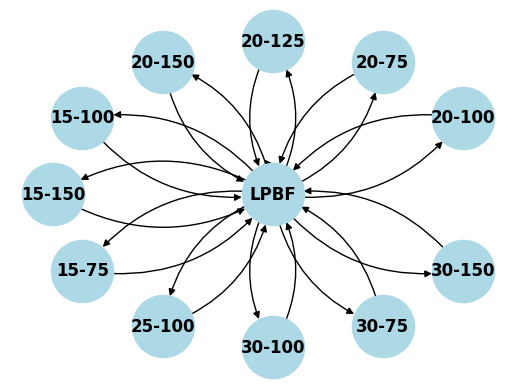

In [13]:
# Visualize the graph
nx.draw_networkx(G, pos, with_labels=True, node_color='lightblue', node_size=2000, font_weight='bold', connectionstyle='arc3,rad=0.3')

plt.axis("off")
plt.show()


- we use the **draw_networkx function** from NetworkX to visualize the graph G using the specified positions pos.

- G: The graph object to be visualized.
- pos: The positions of the nodes in the graph.
- with_labels=True: Specifies that the node labels should be displayed on the visualization.
- node_color='lightblue': Sets the color of the nodes to 'lightblue'.
- node_size=1000: Sets the size of the nodes to 1000.
- font_weight='bold': Sets the font weight of the node labels to 'bold'.
- connectionstyle='arc3,rad=0.2': Specifies the style of the edges as curved arcs with a curvature of 0.2.
- After creating the visualization, we use plt.axis("off") to turn off the axis display.
- plt.show() to display the graph visualization.

This step allows us to see a visual representation of the graph, with nodes represented as circles, edges as curved arcs, and labels displayed for each node.